Code to plot spin split Andreev Bound Spectrum E vs phi

In [31]:
import sys
from pathlib import Path
import numpy as np
#from numpy.linalg import eigvals, eigvalsh
#from scipy.linalg import eigh
from scipy.sparse.linalg import eigsh,eigs
import matplotlib.pyplot as plt
import math, cmath
import sys
import os
import joblib
from pathlib import Path
import pickle
import time
from mpl_toolkits.mplot3d import Axes3D
from scipy.sparse import csr_matrix, coo_matrix,  bmat, diags, identity, issparse, vstack, hstack

#import sys  
sys.path.insert(1,'C:\\Users\\avani\\Desktop\\Spin_Splitting_Ge_ABS')

import Minimal_Model_1D as M

hbar = 1.055*10**(-34);   #in J-s
ee = 1.602*10**(-19);     #in C
hbar_mev = hbar/ee*1000   # in meV-s
me = 9.11*10**(-31);      #in kg
hbm = hbar**2*1000/2/me/ee/(1e-18) #in meV (nm)**2

In [34]:
NSM = 65          # in nm
MY = 3             # no of subbands
AX = 1             # lattice spacing in nm
LY = 100           # Width in nm
ALPHAT = 0        # meV-nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge
OMEGA = 2*4*hbm/LY**2/MEFF_SC
NSC = 2000
N = 2*NSC + NSM



print('first subband energy =' , OMEGA/2 , '\n', 'second subband energy =' , 3*OMEGA/2)

MU_SC =  OMEGA   #in between two subbands
MU_SM =  OMEGA   #in between two subbands

print('mu_sc = ',MU_SC)

PHI = np.linspace(-1*np.pi,1*np.pi,101)
K = 12

Ep = np.empty((PHI.shape[0],K))

D = M.oneD_Minimal_Model(N,NSM, NSC,MY,AX ,OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)

for i in range(PHI.shape[0]):

    H = D.H_sys(PHI[i], so='li' )
    
    E = eigsh(H,k=K,sigma=0, return_eigenvectors=False)
    
    Ep[i,:] =np.sort(E)
    
    if i%10==0:
        print(i)

first subband energy = 0.6631720133634798 
 second subband energy = 1.9895160400904393
mu_sc =  1.3263440267269595
0
10
20
30
40
50
60
70
80
90
100


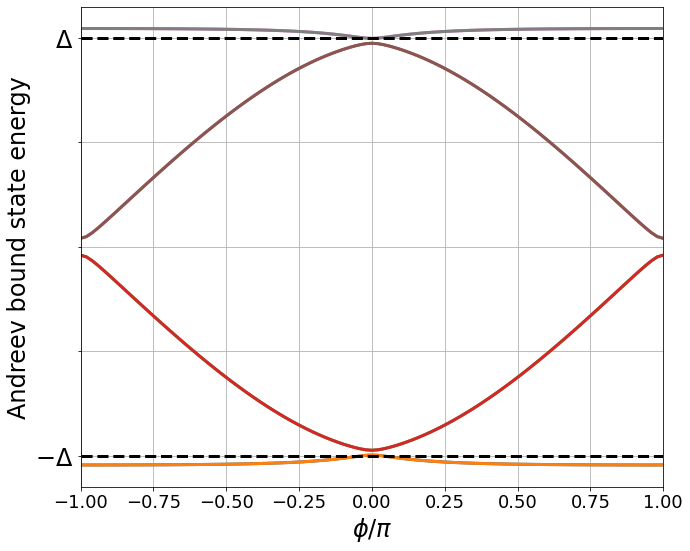

In [47]:

plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))
#f = plt.figure(figsize=(16, 10))
# Define line styles and colors
#line_styles = ['solid', 'solid', 'solid', 'solid', 'solid']
#line_colors = ['blue', 'red', 'blue', 'red', 'blue']

ax = plt.axes()

#Ep2 = Ep[:,2:6]
Ep2 = Ep[:,2:10]

for i in range(Ep2.shape[1]):
    #plt.plot(PHI/np.pi, Ep[:,i]/DELTA, lw=3, color=line_colors[i], linestyle=line_styles[i])
    plt.plot(PHI/np.pi, Ep2[:,i]/DELTA, lw=3)

# Increase the font size of the axes labels and title
plt.xlabel(r'$\phi/\pi$', fontsize=24)
plt.ylabel(r'Andreev bound state energy', fontsize=24)
#plt.title(r'$E$ vs. $\phi$ for Ly = %i' %LY, fontsize=24)

plt.grid(True)
#plt.legend(['E1', 'E2', 'E3', 'E4', 'E5'])

# Set x-axis limits to -1 and +1
plt.xlim(-1, 1)
#plt.ylim(-0.5, 0.5)

plt.tight_layout()

# Increase the number of ticks on the x-axis
#plt.xticks(np.linspace(-1, 1, num=10))


# Specify ticks on the y-axis 
ax.set_yticks(np.linspace(-1,1,num=5))

# setting label for y tick 
ax.set_yticklabels([r'$-\Delta$','','','', r'$\Delta$'], fontsize=24) 



# Add dashed lines at +1 and -1 on the y-axis
plt.axhline(1, color='black', linestyle='dashed', lw=3)
plt.axhline(-1, color='black', linestyle='dashed', lw=3)

# Adjust subplot parameters to remove white space
#plt.subplots_adjust(left=0.08, bottom=0.08, right=0.95, top=0.92)

# Save the plot as an image file
#plt.savefig(os.path.join(folder_loc, 'E_vs_phi_v1.png'))

plt.show()

In [40]:
NSM = 65          # in nm
MY = 3             # no of subbands
AX = 1             # lattice spacing in nm
LY = 100           # Width in nm
ALPHAT = 78        # meV-nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge
OMEGA = 2*4*hbm/LY**2/MEFF_SC
NSC = 2000
N = 2*NSC + NSM



print('first subband energy =' , OMEGA/2 , '\n', 'second subband energy =' , 3*OMEGA/2)

MU_SC =  OMEGA   #in between two subbands
MU_SM =  OMEGA   #in between two subbands

print('mu_sc = ',MU_SC)

PHI = np.linspace(-1*np.pi,1*np.pi,101)
K = 12

Ep_s = np.empty((PHI.shape[0],K))

D = M.oneD_Minimal_Model(N,NSM, NSC,MY,AX ,OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)

for i in range(PHI.shape[0]):

    H = D.H_sys(PHI[i], so='li' )
    
    E = eigsh(H,k=K,sigma=0, return_eigenvectors=False)
    
    Ep_s[i,:] =np.sort(E)
    
    if i%10==0:
        print(i)

first subband energy = 0.6631720133634798 
 second subband energy = 1.9895160400904393
mu_sc =  1.3263440267269595
0
10
20
30
40
50
60
70
80
90
100


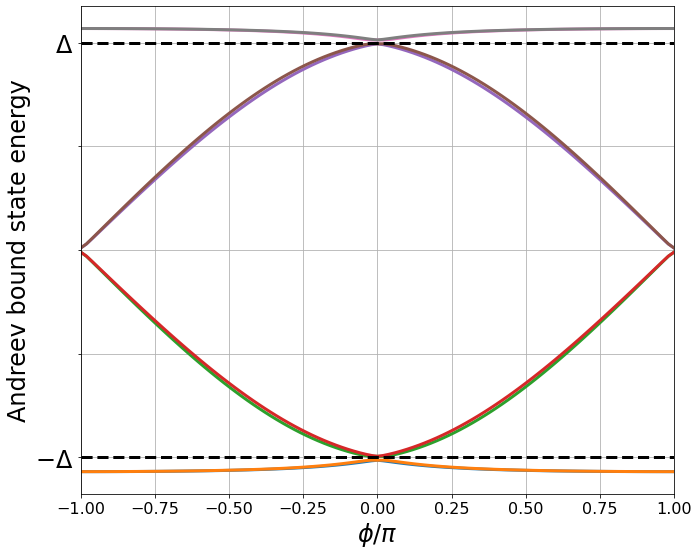

In [44]:

plt.rc('font', size=16)

f = plt.figure(figsize=(10, 8))
#f = plt.figure(figsize=(16, 10))
# Define line styles and colors
#line_styles = ['solid', 'solid', 'solid', 'solid', 'solid']
#line_colors = ['blue', 'red', 'blue', 'red', 'blue']

ax = plt.axes()

#Ep2 = Ep[:,2:6]
Ep2_s = Ep_s[:,2:10]

for i in range(Ep2_s.shape[1]):
    #plt.plot(PHI/np.pi, Ep[:,i]/DELTA, lw=3, color=line_colors[i], linestyle=line_styles[i])
    plt.plot(PHI/np.pi, Ep2_s[:,i]/DELTA, lw=3)

# Increase the font size of the axes labels and title
plt.xlabel(r'$\phi/\pi$', fontsize=24)
plt.ylabel(r'Andreev bound state energy', fontsize=24)
#plt.title(r'$E$ vs. $\phi$ for Ly = %i' %LY, fontsize=24)

plt.grid(True)
#plt.legend(['E1', 'E2', 'E3', 'E4', 'E5'])

# Set x-axis limits to -1 and +1
plt.xlim(-1, 1)
#plt.ylim(-0.5, 0.5)

plt.tight_layout()

# Increase the number of ticks on the x-axis
#plt.xticks(np.linspace(-1, 1, num=10))

# Increase the number of ticks on the y-axis
#plt.yticks(np.linspace(np.min(Ep2), np.max(Ep2), num=10))

# Specify ticks on the y-axis 
ax.set_yticks(np.linspace(-1,1,num=5))

# setting label for y tick 
ax.set_yticklabels([r'$-\Delta$','','','', r'$\Delta$'], fontsize=24) 


# Add dashed lines at +1 and -1 on the y-axis
plt.axhline(1, color='black', linestyle='dashed', lw=3)
plt.axhline(-1, color='black', linestyle='dashed', lw=3)

# Adjust subplot parameters to remove white space
#plt.subplots_adjust(left=0.08, bottom=0.08, right=0.95, top=0.92)

# Save the plot as an image file
#plt.savefig(os.path.join(folder_loc, 'E_vs_phi_v1.png'))

plt.show()

In [45]:
NSM = 100          # in nm
MY = 3             # no of subbands
AX = 1             # lattice spacing in nm
LY = 100           # Width in nm
ALPHAT = 78        # meV-nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge
OMEGA = 2*4*hbm/LY**2/MEFF_SC
NSC = 2000
N = 2*NSC + NSM



print('first subband energy =' , OMEGA/2 , '\n', 'second subband energy =' , 3*OMEGA/2)

MU_SC =  OMEGA   #in between two subbands
MU_SM =  OMEGA   #in between two subbands

print('mu_sc = ',MU_SC)

PHI = np.linspace(-1*np.pi,1*np.pi,101)
K = 12

Ep_s = np.empty((PHI.shape[0],K))

D = M.oneD_Minimal_Model(N,NSM, NSC,MY,AX ,OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)

for i in range(PHI.shape[0]):

    H = D.H_sys(PHI[i], so='li' )
    
    E = eigsh(H,k=K,sigma=0, return_eigenvectors=False)
    
    Ep_s[i,:] =np.sort(E)
    
    if i%10==0:
        print(i)

first subband energy = 0.6631720133634798 
 second subband energy = 1.9895160400904393
mu_sc =  1.3263440267269595
0
10
20


KeyboardInterrupt: 